# CaféScore · Entrega final: segunda vuelta de CRISP-DM y despliegue
Minería de Datos (ADMI 2559) · Tomás Barrera, Valentina Hernández, María Paz Luna y María Lucía Rincón

## 1. Cargar paquetes

In [1]:
%pip install -q shap

In [2]:
import warnings
warnings.filterwarnings("ignore")
import os
import sys
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, silhouette_score
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler

## 2. Configuración

In [3]:
ARCHIVO = "cafescore_data.csv"
CARPETA_APP = "plantilla_app"
COSTO_FN = 60
COSTO_FP = 20
PORCENTAJE_PRUEBA = 0.2
K = 5
PERCENTIL_TOPE = 0.99
N_MUESTRAS = 1000
SEMILLA = 2559
K_SEGMENTOS = 5
ARRIENDO_MAXIMO = 12
AREA_LOCAL = 80
ARRIENDO_CHAPINERO = 6.5
MARGEN_TIENDA = 15
RADIO_CANIBALIZACION = 1000
SEPARACION_MINIMA = 500

tiendas = pd.DataFrame({"tienda": ["Chapinero", "Teusaquillo", "Usaquén"],
                        "lat": [4.6486, 4.6318, 4.6950], "lon": [-74.0628, -74.0726, -74.0306]})

### 2.1 Qué cambió desde la ficha y desde la entrega 1

## 3. Datos, target y costo

In [4]:
if ARCHIVO.endswith(".csv"):
    datos = pd.read_csv(ARCHIVO)
else:
    datos = pd.read_excel(ARCHIVO)
datos["hay_cafe"] = (datos["n_cafes"] >= 1).astype(int)

def costo(real, decision):
    falsos_negativos = ((real == 1) & (decision == 0)).sum()
    falsos_positivos = ((real == 0) & (decision == 1)).sum()
    return COSTO_FN * falsos_negativos + COSTO_FP * falsos_positivos

print("Filas al cargar:", len(datos))
datos = datos[~datos["h3"].duplicated()]
datos = datos[datos["n_manzanas"] > 0]
datos = datos[datos["valor_suelo_m2"] > 0].reset_index(drop=True)
print("Filas después de los filtros:", len(datos))
print("Tasa base:", round(datos["hay_cafe"].mean() * 100, 1), "%")

Filas al cargar: 3275
Filas después de los filtros: 3275
Tasa base: 25.1 %


In [5]:
NEGOCIOS = ["ov_servicios_empresas_300m", "ov_comercio_300m", "ov_educacion_300m", "ov_salud_300m",
            "ov_belleza_estilo_300m", "ov_hoteles_300m", "ov_entretenimiento_300m", "ov_deporte_300m"]
GENERADORES = ["osm_universidades_300m", "osm_colegios_300m", "osm_oficinas_osm_300m", "osm_bancos_300m",
               "osm_centros_comerciales_300m", "osm_hospitales_clinicas_300m"]

def construir(tabla):
    tabla = tabla.copy()
    tabla["log_valor_suelo"] = np.log(tabla["valor_suelo_m2"])
    tabla["log_tm_flujo_mes"] = np.log(tabla["tm_flujo_mes"])
    tabla["negocios_total_300m"] = tabla[NEGOCIOS].sum(axis=1)
    proporciones = tabla[NEGOCIOS].div(tabla["negocios_total_300m"].replace(0, np.nan), axis=0)
    entropia = -(proporciones * np.log(proporciones.where(proporciones > 0))).sum(axis=1)
    tabla["diversidad_usos"] = (entropia / np.log(len(NEGOCIOS))).fillna(0).abs()
    tabla["tipos_generadores"] = (tabla[GENERADORES] > 0).sum(axis=1)
    hay_oficinas = (tabla["osm_oficinas_osm_300m"] > 0) | (tabla["fsq_oficinas_hist_300m"] >= 20)
    hay_universidad = tabla["osm_universidades_300m"] > 0
    tabla["oficinas_y_universidad"] = (hay_oficinas & hay_universidad).astype(int)
    tabla["accesibilidad_tm"] = tabla["tm_flujo_mes"] / 100000 * np.exp(-tabla["dist_tm_m"] / 500)
    tabla["oficinas_x_tm"] = tabla["osm_oficinas_osm_300m"] * tabla["accesibilidad_tm"]
    tabla["oficinas_fsq_x_tm"] = tabla["fsq_oficinas_hist_300m"] * tabla["accesibilidad_tm"]
    tabla["empresas_x_tm"] = tabla["ov_servicios_empresas_300m"] * tabla["accesibilidad_tm"]
    return tabla

todas = construir(datos)
NUEVAS = ["negocios_total_300m", "diversidad_usos", "tipos_generadores", "oficinas_y_universidad", "accesibilidad_tm"]
ENTRADAS_ENTREGA1 = (["n_manzanas", "log_valor_suelo"] + NEGOCIOS + ["fsq_negocios_hist_300m", "fsq_oficinas_hist_300m"]
            + GENERADORES + ["osm_parques_300m", "osm_paraderos_sitp_300m"]
            + ["dist_tm_m", "tm_a_500m", "log_tm_flujo_mes"] + NUEVAS)
NO_CONTEOS = ["log_valor_suelo", "log_tm_flujo_mes", "tm_a_500m", "diversidad_usos",
              "oficinas_y_universidad", "tipos_generadores"]
print("Variables de entrada en la entrega 1:", len(ENTRADAS_ENTREGA1))

Variables de entrada en la entrega 1: 28


## 4. Partición por bloques y validación cruzada
El 20 % de los bloques se guarda para la prueba, con la misma semilla de la entrega 1. Dentro del entrenamiento, cada bloque va a uno de 5 batches.

In [6]:
bloques = np.sort(todas["bloque"].unique())
azar = np.random.default_rng(SEMILLA)
bloques_prueba = azar.choice(bloques, size=round(PORCENTAJE_PRUEBA * len(bloques)), replace=False)
todas["parte"] = np.where(todas["bloque"].isin(bloques_prueba), "prueba", "entrenamiento")
entrenamiento = todas[todas["parte"] == "entrenamiento"].reset_index(drop=True)
prueba = todas[todas["parte"] == "prueba"].reset_index(drop=True)

bloques_ent = np.sort(entrenamiento["bloque"].unique())
azar = np.random.default_rng(SEMILLA)
bloques_revueltos = azar.permutation(bloques_ent)
entrenamiento["batch"] = entrenamiento["bloque"].map(dict(zip(bloques_revueltos, np.arange(len(bloques_revueltos)) % K)))
todas.groupby("parte").agg(bloques=("bloque", "nunique"), celdas=("h3", "size"), tasa_base=("hay_cafe", "mean")).round(3)

,bloques,celdas,tasa_base
parte,,,
entrenamiento,86,2543,0.268
prueba,22,732,0.193


In [7]:
def preparar(tabla, referencia, columnas, para_logistica):
    conteos = [c for c in columnas if c not in NO_CONTEOS]
    tope = referencia[conteos].quantile(PERCENTIL_TOPE)
    X = tabla[columnas].copy()
    X[conteos] = X[conteos].clip(upper=tope, axis=1)
    if para_logistica:
        X_ref = referencia[columnas].copy()
        X_ref[conteos] = np.log1p(X_ref[conteos].clip(upper=tope, axis=1))
        X[conteos] = np.log1p(X[conteos])
        X = (X - X_ref.mean()) / X_ref.std()
    return X

def validacion_cruzada(modelo, columnas, para_logistica):
    probabilidad = np.zeros(len(entrenamiento))
    for numero in range(K):
        en_batch = entrenamiento["batch"] == numero
        parte_ent = entrenamiento[~en_batch]
        parte_val = entrenamiento[en_batch]
        modelo.fit(preparar(parte_ent, parte_ent, columnas, para_logistica), parte_ent["hay_cafe"])
        probabilidad[en_batch.values] = modelo.predict_proba(preparar(parte_val, parte_ent, columnas, para_logistica))[:, 1]
    return probabilidad

UMBRALES = np.round(np.arange(0.02, 0.91, 0.01), 2)

def mejor_umbral(probabilidad):
    costos = [costo(entrenamiento["hay_cafe"], (probabilidad >= u).astype(int)) for u in UMBRALES]
    mejor = np.argmin(costos)
    return UMBRALES[mejor], costos[mejor], costos

### 4.1 Revisión de las variables construidas
Cada variable construida se queda solo si quitarla sube el costo en la validación cruzada. Se prueba con la regresión logística, el modelo elegido en la entrega 1, con los mismos valores de C. También se prueban tres variables nuevas que traen algo que las columnas originales no tienen por separado: oficinas o servicios a empresas cerca de una estación de TransMilenio con mucho flujo (el conteo multiplicado por accesibilidad_tm). Todo se decide con el entrenamiento; la prueba no se toca.

In [8]:
def costo_logistica(columnas):
    costos = []
    for C in [0.01, 0.1, 1, 10]:
        p = validacion_cruzada(LogisticRegression(C=C, max_iter=2000), columnas, True)
        costos.append(mejor_umbral(p)[1])
    return min(costos)

SIN_DOS = [c for c in ENTRADAS_ENTREGA1 if c not in ["negocios_total_300m", "diversidad_usos"]]
candidatas_variables = {"Las 28 de la entrega 1": ENTRADAS_ENTREGA1}
for c in NUEVAS:
    candidatas_variables["Sin " + c] = [x for x in ENTRADAS_ENTREGA1 if x != c]
candidatas_variables["Sin negocios_total_300m ni diversidad_usos"] = SIN_DOS
for c in ["tipos_generadores", "oficinas_y_universidad", "accesibilidad_tm"]:
    candidatas_variables["Sin esas dos ni " + c] = [x for x in SIN_DOS if x != c]
candidatas_variables["Sin esas dos + oficinas OSM × TransMilenio"] = SIN_DOS + ["oficinas_x_tm"]
candidatas_variables["Sin esas dos + oficinas Foursquare × TransMilenio"] = SIN_DOS + ["oficinas_fsq_x_tm"]
candidatas_variables["Sin esas dos + servicios a empresas × TransMilenio"] = SIN_DOS + ["empresas_x_tm"]

revision = pd.DataFrame({"Variables": list(candidatas_variables),
                         "Número": [len(v) for v in candidatas_variables.values()],
                         "Costo validación (M)": [costo_logistica(v) for v in candidatas_variables.values()]})
revision["Frente a la entrega 1 (M)"] = revision["Costo validación (M)"] - revision.loc[0, "Costo validación (M)"]
revision

,Variables,Número,Costo validación (M),Frente a la entrega 1 (M)
0,Las 28 de la entrega 1,28,19640,0
1,Sin negocios_total_300m,27,19620,-20
2,Sin diversidad_usos,27,19520,-120
3,Sin tipos_generadores,27,19740,100
4,Sin oficinas_y_universidad,27,19600,-40
5,Sin accesibilidad_tm,27,19480,-160
6,Sin negocios_total_300m ni diversidad_usos,26,19460,-180
7,Sin esas dos ni tipos_generadores,25,19700,60
8,Sin esas dos ni oficinas_y_universidad,25,19600,-40
9,Sin esas dos ni accesibilidad_tm,25,19500,-140


In [9]:
ELEGIDAS = revision.loc[revision["Costo validación (M)"].idxmin(), "Variables"]
ENTRADAS = candidatas_variables[ELEGIDAS]
conteos = [c for c in ENTRADAS if c not in NO_CONTEOS]
print("Se quedan:", ELEGIDAS, "|", len(ENTRADAS), "variables")

Se quedan: Sin esas dos + oficinas OSM × TransMilenio | 27 variables


## 5. Primera vuelta: regla simple, regresión logística y árbol
Los mismos cortes y parámetros que se probaron en la entrega 1.

In [10]:
def regla(tabla, N):
    return (tabla["ov_comercio_300m"] >= N).astype(int)

costos_regla = [costo(entrenamiento["hay_cafe"], regla(entrenamiento, N)) for N in range(0, 301)]
N_REGLA = int(np.argmin(costos_regla))
print("Regla simple: estudiar si hay", N_REGLA, "comercios o más a 300 m")

Regla simple: estudiar si hay 51 comercios o más a 300 m


In [11]:
comparacion = []

mejor_log = None
for C in [0.01, 0.1, 1, 10]:
    p = validacion_cruzada(LogisticRegression(C=C, max_iter=2000), ENTRADAS, True)
    umbral, costo_val, _ = mejor_umbral(p)
    if mejor_log is None or costo_val < mejor_log["Costo validación (M)"]:
        mejor_log = {"Modelo": "Regresión logística", "Parámetros": "C = " + str(C), "AUC validación": round(roc_auc_score(entrenamiento["hay_cafe"], p), 3),
                     "Umbral": umbral, "Costo validación (M)": costo_val}
        C_ELEGIDO = C
comparacion.append(mejor_log)

mejor_arbol = None
for profundidad in [2, 3, 4, 5]:
    for hoja in [10, 50]:
        p = validacion_cruzada(DecisionTreeClassifier(max_depth=profundidad, min_samples_leaf=hoja, random_state=SEMILLA), ENTRADAS, False)
        umbral, costo_val, _ = mejor_umbral(p)
        auc = round(roc_auc_score(entrenamiento["hay_cafe"], p), 3)
        if mejor_arbol is None or (costo_val, -auc) < (mejor_arbol["Costo validación (M)"], -mejor_arbol["AUC validación"]):
            mejor_arbol = {"Modelo": "Árbol de decisión", "Parámetros": "profundidad " + str(profundidad) + ", hoja " + str(hoja),
                           "AUC validación": auc, "Umbral": umbral, "Costo validación (M)": costo_val}
            PROFUNDIDAD, HOJA = profundidad, hoja
comparacion.append(mejor_arbol)
pd.DataFrame(comparacion)

,Modelo,Parámetros,AUC validación,Umbral,Costo validación (M)
0,Regresión logística,C = 10,0.830,0.23,19440
1,Árbol de decisión,"profundidad 3, hoja 10",0.807,0.24,20580


## 6. Segunda vuelta: bosque aleatorio y XGBoost
Los dos son ensambles de árboles, así que se comparan con el árbol de decisión. Se usa la misma validación cruzada por bloques y el umbral se elige con el mismo costo.

In [12]:
mejor_bosque = None
for hoja in [1, 5, 10, 20]:
    for variables in ["sqrt", 0.5]:
        bosque = RandomForestClassifier(n_estimators=200, min_samples_leaf=hoja, max_features=variables, random_state=SEMILLA, n_jobs=-1)
        p = validacion_cruzada(bosque, ENTRADAS, False)
        umbral, costo_val, _ = mejor_umbral(p)
        if mejor_bosque is None or costo_val < mejor_bosque["Costo validación (M)"]:
            mejor_bosque = {"Modelo": "Bosque aleatorio", "Parámetros": "hoja " + str(hoja) + ", variables " + str(variables),
                            "AUC validación": round(roc_auc_score(entrenamiento["hay_cafe"], p), 3), "Umbral": umbral, "Costo validación (M)": costo_val}
            HOJA_BOSQUE, VARIABLES_BOSQUE = hoja, variables
comparacion.append(mejor_bosque)

mejor_xgb = None
for profundidad in [2, 3, 4]:
    for tasa in [0.05, 0.1]:
        xgb = XGBClassifier(n_estimators=100, max_depth=profundidad, learning_rate=tasa, subsample=0.8, colsample_bytree=0.8, random_state=SEMILLA)
        p = validacion_cruzada(xgb, ENTRADAS, False)
        umbral, costo_val, _ = mejor_umbral(p)
        if mejor_xgb is None or costo_val < mejor_xgb["Costo validación (M)"]:
            mejor_xgb = {"Modelo": "XGBoost", "Parámetros": "profundidad " + str(profundidad) + ", tasa " + str(tasa),
                         "AUC validación": round(roc_auc_score(entrenamiento["hay_cafe"], p), 3), "Umbral": umbral, "Costo validación (M)": costo_val}
            PROFUNDIDAD_XGB, TASA_XGB = profundidad, tasa
comparacion.append(mejor_xgb)

comparacion = pd.DataFrame(comparacion).set_index("Modelo")
comparacion

,Parámetros,AUC validación,Umbral,Costo validación (M)
Modelo,,,,
Regresión logística,C = 10,0.830,0.23,19440
Árbol de decisión,"profundidad 3, hoja 10",0.807,0.24,20580
Bosque aleatorio,"hoja 10, variables sqrt",0.829,0.26,19760
XGBoost,"profundidad 2, tasa 0.05",0.827,0.25,19940


### 6.1 Modelo elegido
El que cuesta menos en la validación cruzada. La prueba no se usa para elegir.

In [13]:
MODELO_ELEGIDO = comparacion["Costo validación (M)"].idxmin()
UMBRAL = comparacion.loc[MODELO_ELEGIDO, "Umbral"]
print("Modelo elegido:", MODELO_ELEGIDO, "| umbral:", UMBRAL)

Modelo elegido: Regresión logística | umbral: 0.23


## 7. Tabla de modelos ampliada (zonas de prueba)
La prueba son los mismos 22 bloques de la entrega 1 (semilla 2559). Cada modelo, ya elegido en la validación cruzada, se entrena con todo el entrenamiento y se mide una sola vez en la prueba.

In [14]:
modelos = {
    "Regresión logística": (LogisticRegression(C=C_ELEGIDO, max_iter=2000), True),
    "Árbol de decisión": (DecisionTreeClassifier(max_depth=PROFUNDIDAD, min_samples_leaf=HOJA, random_state=SEMILLA), False),
    "Bosque aleatorio": (RandomForestClassifier(n_estimators=200, min_samples_leaf=HOJA_BOSQUE, max_features=VARIABLES_BOSQUE, random_state=SEMILLA, n_jobs=-1), False),
    "XGBoost": (XGBClassifier(n_estimators=100, max_depth=PROFUNDIDAD_XGB, learning_rate=TASA_XGB, subsample=0.8, colsample_bytree=0.8, random_state=SEMILLA), False),
}
real = prueba["hay_cafe"].values
puntajes = {"Regla simple": prueba["ov_comercio_300m"].values}
decisiones = {"Estudiar todas": np.ones(len(prueba), dtype=int),
              "No estudiar ninguna": np.zeros(len(prueba), dtype=int),
              "Regla simple": regla(prueba, N_REGLA).values}
for nombre, (modelo, para_logistica) in modelos.items():
    modelo.fit(preparar(entrenamiento, entrenamiento, ENTRADAS, para_logistica), entrenamiento["hay_cafe"])
    puntajes[nombre] = modelo.predict_proba(preparar(prueba, entrenamiento, ENTRADAS, para_logistica))[:, 1]
    decisiones[nombre] = (puntajes[nombre] >= comparacion.loc[nombre, "Umbral"]).astype(int)
modelo_log = modelos["Regresión logística"][0]

def medir(real, decision):
    VP = ((decision == 1) & (real == 1)).sum()
    FP = ((decision == 1) & (real == 0)).sum()
    FN = ((decision == 0) & (real == 1)).sum()
    VN = ((decision == 0) & (real == 0)).sum()
    return {"Zonas a estudiar": VP + FP, "VP": VP, "FP": FP, "FN": FN, "VN": VN,
            "Costo (M)": COSTO_FN * FN + COSTO_FP * FP,
            "Sensibilidad": VP / max(VP + FN, 1), "Precisión": VP / max(VP + FP, 1)}

resultados = pd.DataFrame([medir(real, decision) for decision in decisiones.values()], index=list(decisiones))
resultados.round(3)

,Zonas a estudiar,VP,FP,FN,VN,Costo (M),Sensibilidad,Precisión
Estudiar todas,732,141,591,0,0,11820,1.000,0.193
No estudiar ninguna,0,0,0,141,591,8460,0.000,0.000
Regla simple,266,96,170,45,421,6100,0.681,0.361
Regresión logística,258,96,162,45,429,5940,0.681,0.372
Árbol de decisión,197,81,116,60,475,5920,0.574,0.411
Bosque aleatorio,263,101,162,40,429,5640,0.716,0.384
XGBoost,265,98,167,43,424,5920,0.695,0.370


### 7.1 Intervalos de confianza y diferencia con la regla
1.000 muestras de bloques de prueba con repetición. En cada muestra se mide todo y se calcula la diferencia de costo de cada modelo con la regla simple. Si el intervalo de la diferencia incluye el 0, no se puede afirmar que el modelo le gane a la regla.

In [15]:
bloque = prueba["bloque"].values
lista_bloques = np.unique(bloque)
azar = np.random.default_rng(SEMILLA)
muestras = []
for i in range(N_MUESTRAS):
    elegidos = azar.choice(lista_bloques, len(lista_bloques))
    filas_muestra = np.concatenate([np.where(bloque == b)[0] for b in elegidos])
    for nombre, decision in decisiones.items():
        medidas = medir(real[filas_muestra], decision[filas_muestra])
        if nombre in puntajes:
            medidas["AUC"] = roc_auc_score(real[filas_muestra], puntajes[nombre][filas_muestra])
        medidas["Opción"] = nombre
        medidas["Muestra"] = i
        muestras.append(medidas)
muestras = pd.DataFrame(muestras)

def intervalo(valores, decimales):
    bajo, alto = np.percentile(valores, [2.5, 97.5]).round(decimales)
    if decimales == 0:
        bajo, alto = int(bajo), int(alto)
    return "[" + str(bajo) + "; " + str(alto) + "]"

costo_regla_muestras = muestras.loc[muestras["Opción"] == "Regla simple", "Costo (M)"].values
tabla_final = []
for nombre in decisiones:
    m = muestras[muestras["Opción"] == nombre]
    fila = {"Opción": nombre, "Zonas a estudiar": resultados.loc[nombre, "Zonas a estudiar"],
            "Costo (M)": resultados.loc[nombre, "Costo (M)"], "IC 95 % costo": intervalo(m["Costo (M)"], 0),
            "Sensibilidad": round(resultados.loc[nombre, "Sensibilidad"], 3), "Precisión": round(resultados.loc[nombre, "Precisión"], 3)}
    if nombre in puntajes:
        fila["AUC"] = round(roc_auc_score(real, puntajes[nombre]), 3)
        fila["IC 95 % AUC"] = intervalo(m["AUC"], 3)
    if nombre in modelos:
        diferencia = m["Costo (M)"].values - costo_regla_muestras
        fila["Diferencia con la regla (M)"] = resultados.loc[nombre, "Costo (M)"] - resultados.loc["Regla simple", "Costo (M)"]
        fila["IC 95 % diferencia"] = intervalo(diferencia, 0)
        fila["% de muestras en que cuesta menos"] = round((diferencia < 0).mean() * 100)
    tabla_final.append(fila)
tabla_final = pd.DataFrame(tabla_final).set_index("Opción").fillna("")
tabla_final

,Zonas a estudiar,Costo (M),IC 95 % costo,Sensibilidad,Precisión,AUC,IC 95 % AUC,Diferencia con la regla (M),IC 95 % diferencia,% de muestras en que cuesta menos
Opción,,,,,,,,,,
Estudiar todas,732,11820,[9418; 13980],1.000,0.193,,,,,
No estudiar ninguna,0,8460,[4980; 12300],0.000,0.000,,,,,
Regla simple,266,6100,[4140; 8220],0.681,0.361,0.768,[0.714; 0.813],,,
Regresión logística,258,5940,[4080; 7880],0.681,0.372,0.78,[0.724; 0.82],-160.0,[-820; 380],71.0
Árbol de decisión,197,5920,[3980; 8020],0.574,0.411,0.759,[0.71; 0.793],-180.0,[-1040; 640],69.0
Bosque aleatorio,263,5640,[3920; 7400],0.716,0.384,0.789,[0.733; 0.826],-460.0,[-1220; 200],90.0
XGBoost,265,5920,[4039; 7880],0.695,0.370,0.787,[0.732; 0.825],-180.0,[-840; 320],73.0


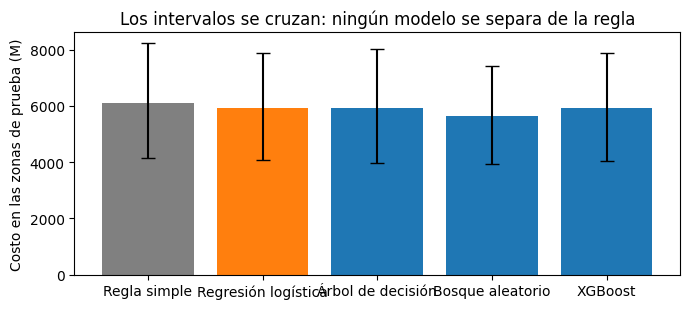

In [16]:
opciones = ["Regla simple"] + list(modelos)
bajos = [resultados.loc[n, "Costo (M)"] - np.percentile(muestras.loc[muestras["Opción"] == n, "Costo (M)"], 2.5) for n in opciones]
altos = [np.percentile(muestras.loc[muestras["Opción"] == n, "Costo (M)"], 97.5) - resultados.loc[n, "Costo (M)"] for n in opciones]
colores = ["gray" if n == "Regla simple" else ("tab:orange" if n == MODELO_ELEGIDO else "tab:blue") for n in opciones]
plt.figure(figsize=(7, 3.2))
plt.bar(opciones, resultados.loc[opciones, "Costo (M)"], yerr=[bajos, altos], color=colores, capsize=5)
plt.ylabel("Costo en las zonas de prueba (M)")
plt.title("Los intervalos se cruzan: ningún modelo se separa de la regla")
plt.tight_layout()
plt.savefig("fig_costos_modelos.png", dpi=200)
plt.show()

### 7.2 Matriz de confusión del modelo elegido, en costo

In [17]:
m = resultados.loc[MODELO_ELEGIDO]
pd.DataFrame({"Estudiar": [str(int(m["VP"])) + " zonas · 0 M", str(int(m["FP"])) + " zonas · " + str(int(m["FP"] * COSTO_FP)) + " M"],
              "No estudiar": [str(int(m["FN"])) + " zonas · " + str(int(m["FN"] * COSTO_FN)) + " M", str(int(m["VN"])) + " zonas · 0 M"]},
             index=["Con café", "Sin café"])

,Estudiar,No estudiar
Con café,96 zonas · 0 M,45 zonas · 2700 M
Sin café,162 zonas · 3240 M,429 zonas · 0 M


## 8. Qué explica el modelo
La importancia por permutación mide cuánto baja el AUC en la prueba cuando se revuelven los valores de una variable. SHAP muestra, zona por zona, cuánto sube o baja cada variable la predicción frente a una zona promedio. Las dos dicen qué mira el modelo, no qué pasaría si Cereza cambiara esa variable.

In [18]:
ETIQUETAS = {
    "n_manzanas": "Manzanas en la zona", "log_valor_suelo": "Valor del suelo (log)",
    "ov_servicios_empresas_300m": "Servicios a empresas a 300 m", "ov_comercio_300m": "Comercios a 300 m",
    "ov_educacion_300m": "Negocios de educación a 300 m", "ov_salud_300m": "Negocios de salud a 300 m",
    "ov_belleza_estilo_300m": "Belleza y estilo a 300 m", "ov_hoteles_300m": "Hoteles a 300 m",
    "ov_entretenimiento_300m": "Entretenimiento a 300 m", "ov_deporte_300m": "Deporte a 300 m",
    "fsq_negocios_hist_300m": "Negocios históricos (Foursquare)", "fsq_oficinas_hist_300m": "Oficinas históricas (Foursquare)",
    "osm_universidades_300m": "Universidades a 300 m", "osm_colegios_300m": "Colegios a 300 m",
    "osm_oficinas_osm_300m": "Oficinas a 300 m", "osm_bancos_300m": "Bancos a 300 m",
    "osm_centros_comerciales_300m": "Centros comerciales a 300 m", "osm_hospitales_clinicas_300m": "Hospitales y clínicas a 300 m",
    "osm_parques_300m": "Parques a 300 m", "osm_paraderos_sitp_300m": "Paraderos SITP a 300 m",
    "dist_tm_m": "Distancia a TransMilenio (m)", "tm_a_500m": "TransMilenio a menos de 500 m",
    "log_tm_flujo_mes": "Validaciones de la estación (log)", "negocios_total_300m": "Negocios en total a 300 m",
    "diversidad_usos": "Diversidad de usos", "tipos_generadores": "Tipos de generadores de demanda",
    "oficinas_y_universidad": "Oficinas y universidad a la vez", "accesibilidad_tm": "Accesibilidad a TransMilenio",
    "oficinas_x_tm": "Oficinas cerca de TransMilenio con flujo", "oficinas_fsq_x_tm": "Oficinas (Foursquare) cerca de TransMilenio",
    "empresas_x_tm": "Servicios a empresas cerca de TransMilenio",
}

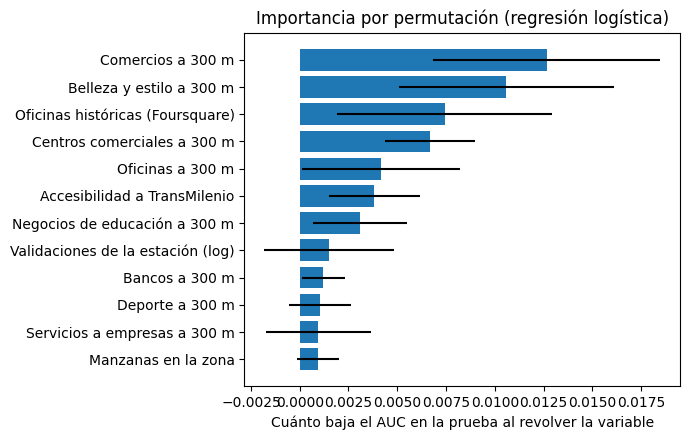

In [19]:
X_ent = preparar(entrenamiento, entrenamiento, ENTRADAS, True)
X_pru = preparar(prueba, entrenamiento, ENTRADAS, True)
permutacion = permutation_importance(modelo_log, X_pru, real, scoring="roc_auc", n_repeats=20, random_state=SEMILLA)
importancia = pd.DataFrame({"Variable": [ETIQUETAS[c] for c in ENTRADAS], "Baja del AUC": permutacion.importances_mean,
                            "DE": permutacion.importances_std}).sort_values("Baja del AUC").tail(12)
plt.figure(figsize=(7, 4.5))
plt.barh(importancia["Variable"], importancia["Baja del AUC"], xerr=importancia["DE"], color="tab:blue")
plt.xlabel("Cuánto baja el AUC en la prueba al revolver la variable")
plt.title("Importancia por permutación (regresión logística)")
plt.tight_layout()
plt.savefig("fig_permutacion.png", dpi=200)
plt.show()

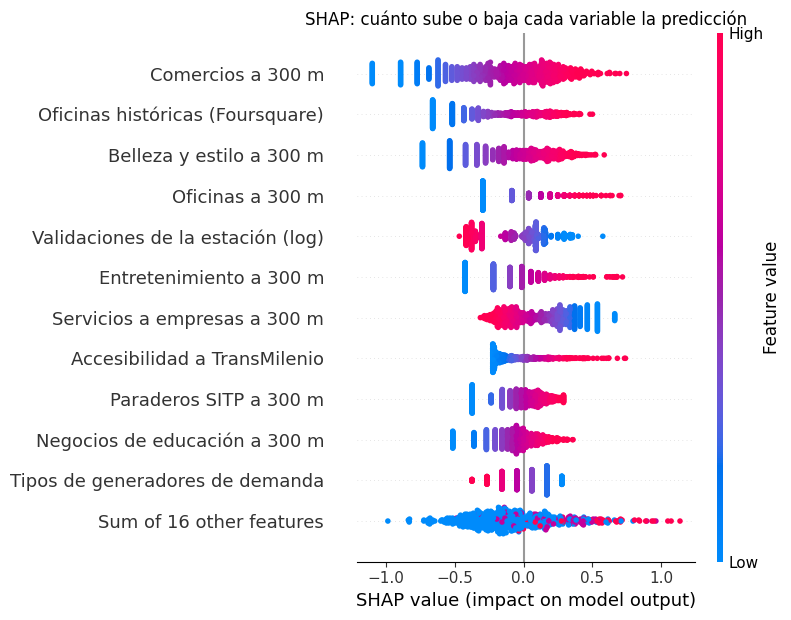

In [20]:
explicador = shap.LinearExplainer(modelo_log, X_ent)
valores_shap = explicador(X_pru)
valores_shap.feature_names = [ETIQUETAS[c] for c in ENTRADAS]
shap.plots.beeswarm(valores_shap, max_display=12, show=False)
plt.title("SHAP: cuánto sube o baja cada variable la predicción")
plt.tight_layout()
plt.savefig("fig_shap.png", dpi=200, bbox_inches="tight")
plt.show()

**Lectura.** Las dos técnicas coinciden: el modelo se apoya sobre todo en cuánto comercio hay alrededor, en las oficinas (las históricas de Foursquare y las de OpenStreetMap) y en señales de una calle activa, como belleza y estilo, entretenimiento y centros comerciales, además de la accesibilidad a TransMilenio. Si se revuelven los comercios, el AUC baja 0,013; con belleza y estilo, 0,011, y con cualquier otra variable menos de 0,008. En SHAP, más comercio y más oficinas suben la predicción (puntos rojos a la derecha).

Tres variables van al revés: más validaciones en la estación, más servicios a empresas y más tipos de generadores bajan la predicción cuando todo lo demás está fijo. No quiere decir que una estación concurrida o una oficina espanten a los cafés. Las estaciones con más validaciones son las de la periferia (ver la segmentación), y los servicios a empresas y los generadores se mueven junto con las oficinas y el comercio, que ya están en el modelo: el modelo solo reparte entre ellas el mismo efecto. Ninguna de estas variables es causa: que haya oficinas cerca de los cafés no garantiza que un café nuevo junto a unas oficinas venda. Además, como los conteos de negocios se mueven juntos, la permutación reparte la importancia entre ellos y cada uno por separado parece menos importante de lo que es.

## 9. Técnica de descubrimiento: segmentación de zonas
Se agrupan todas las zonas de la ciudad según su demanda y su actividad, sin usar los cafés. Cada tipo de zona debe cambiar una acción de Cereza: dónde buscar local y qué concepto de tienda abrir. Elegimos la segmentación porque la pregunta de Cereza es dónde abrir y qué tienda poner allí; las reglas de asociación repetirían lo que ya hace el modelo, y el texto de los nombres solo existe donde ya hay cafés.

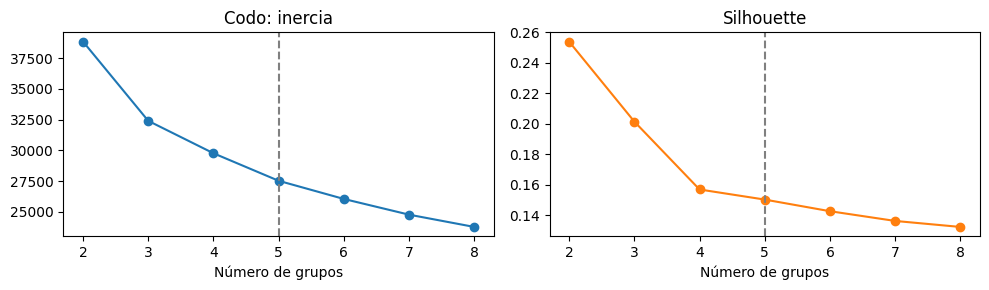

,k,Inercia,Silhouette
0,2,38850.173,0.254
1,3,32404.971,0.201
2,4,29769.425,0.157
3,5,27529.941,0.150
4,6,26053.025,0.143
5,7,24775.835,0.136
6,8,23778.136,0.132


In [21]:
SEGMENTACION = ["negocios_total_300m", "ov_servicios_empresas_300m", "ov_educacion_300m", "ov_salud_300m",
                "ov_entretenimiento_300m", "fsq_oficinas_hist_300m", "osm_universidades_300m", "osm_colegios_300m",
                "osm_oficinas_osm_300m", "osm_bancos_300m", "osm_centros_comerciales_300m", "osm_paraderos_sitp_300m",
                "osm_parques_300m", "valor_suelo_m2", "tm_flujo_mes", "dist_tm_m", "diversidad_usos"]
X_seg = np.log1p(todas[SEGMENTACION].clip(upper=todas[SEGMENTACION].quantile(PERCENTIL_TOPE), axis=1))
X_seg = (X_seg - X_seg.mean()) / X_seg.std()

filas = []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X_seg)
    filas.append({"k": k, "Inercia": kmeans.inertia_, "Silhouette": silhouette_score(X_seg, kmeans.labels_)})
codo = pd.DataFrame(filas)

fig, ejes = plt.subplots(1, 2, figsize=(10, 3))
ejes[0].plot(codo["k"], codo["Inercia"], marker="o")
ejes[0].set_title("Codo: inercia")
ejes[1].plot(codo["k"], codo["Silhouette"], marker="o", color="tab:orange")
ejes[1].set_title("Silhouette")
for eje in ejes:
    eje.axvline(K_SEGMENTOS, color="gray", ls="--")
    eje.set_xlabel("Número de grupos")
plt.tight_layout()
plt.savefig("fig_codo.png", dpi=200)
plt.show()
codo.round(3)

**Por qué 5 grupos.** El silhouette es más alto con 2 grupos, pero 2 grupos solo separan zonas con actividad de zonas sin actividad, y eso ya lo hace el modelo. La inercia no tiene un codo marcado: baja rápido hasta 4 o 5 grupos y después baja poco a poco. Con 5 grupos el centro de negocios queda separado del corredor comercial, y cada uno lleva a una tienda distinta (de oficina frente a de paso). Con 6, el corredor comercial se parte en dos según si hay un centro comercial cerca, sin cambiar ninguna acción. El silhouette es bajo (0,15): los grupos no son tipos puros sino tramos de un continuo de actividad, así que una zona en el borde entre dos grupos se debe mirar con los dos perfiles.

In [22]:
kmeans = KMeans(n_clusters=K_SEGMENTOS, n_init=10, random_state=SEMILLA).fit(X_seg)
todas["grupo"] = kmeans.labels_
orden = todas.groupby("grupo")["negocios_total_300m"].median().sort_values().index
NOMBRES_SEGMENTOS = ["Periferia sin actividad", "Residencial popular", "Residencial con parques y colegios",
                     "Corredor comercial", "Centro de negocios"]
todas["segmento"] = todas["grupo"].map(dict(zip(orden, NOMBRES_SEGMENTOS)))

perfil = todas.groupby("segmento")[SEGMENTACION].median().T.round(1)[NOMBRES_SEGMENTOS]
perfil

segmento,Periferia sin actividad,Residencial popular,Residencial con parques y colegios,Corredor comercial,Centro de negocios
negocios_total_300m,5.0,33.0,135.0,274.5,704.0
ov_servicios_empresas_300m,1.0,8.0,39.0,91.0,258.0
ov_educacion_300m,0.0,3.0,10.0,14.0,41.5
ov_salud_300m,0.0,1.0,6.0,14.0,63.5
ov_entretenimiento_300m,0.0,1.0,3.0,5.0,26.0
fsq_oficinas_hist_300m,0.0,3.0,18.0,82.0,264.0
osm_universidades_300m,0.0,0.0,0.0,0.0,3.0
osm_colegios_300m,0.0,1.0,3.0,2.0,2.0
osm_oficinas_osm_300m,0.0,0.0,1.0,4.0,16.0
osm_bancos_300m,0.0,0.0,0.0,3.0,8.0


Varianza explicada por los dos componentes: 57.9 %


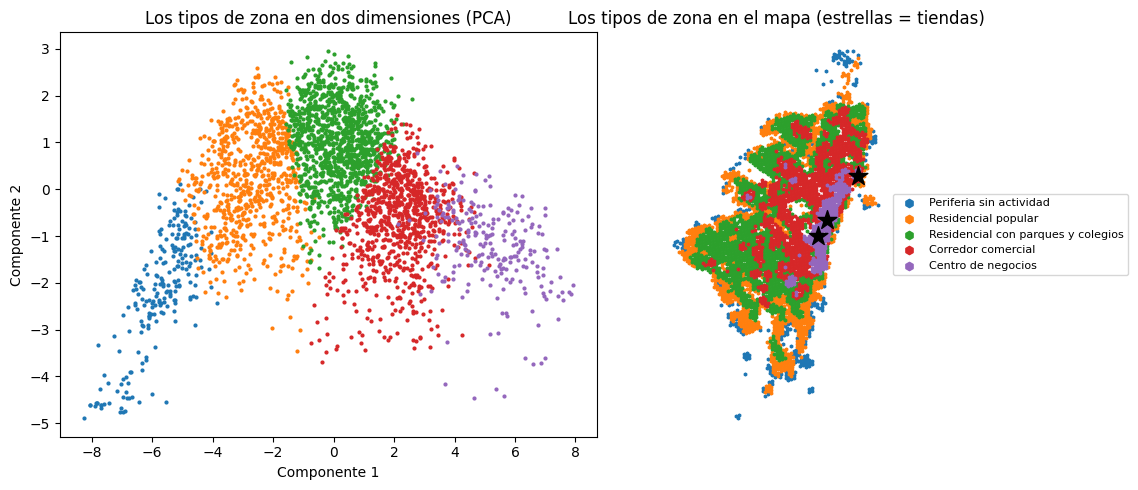

In [23]:
pca = PCA(n_components=2).fit(X_seg)
componentes = pca.transform(X_seg)
print("Varianza explicada por los dos componentes:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for nombre in NOMBRES_SEGMENTOS:
    en_segmento = (todas["segmento"] == nombre).values
    ejes[0].scatter(componentes[en_segmento, 0], componentes[en_segmento, 1], s=4, label=nombre)
    ejes[1].scatter(todas.loc[en_segmento, "lon"], todas.loc[en_segmento, "lat"], s=4, marker="h", label=nombre)
ejes[0].set_xlabel("Componente 1")
ejes[0].set_ylabel("Componente 2")
ejes[0].set_title("Los tipos de zona en dos dimensiones (PCA)")
ejes[1].scatter(tiendas["lon"], tiendas["lat"], marker="*", s=200, color="black")
ejes[1].set_aspect("equal")
ejes[1].axis("off")
ejes[1].set_title("Los tipos de zona en el mapa (estrellas = tiendas)")
ejes[1].legend(markerscale=3, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig("fig_segmentos.png", dpi=200)
plt.show()

In [24]:
ACCIONES = {
    "Centro de negocios": "Primer lugar para buscar local. Tienda de oficina y universidad: barra rápida en la mañana, mesas para trabajar en la tarde, más personal de 7 a 9 a. m. y de 2 a 5 p. m.",
    "Corredor comercial": "Segundo lugar para buscar local, cerca de TransMilenio. Tienda de paso: café para llevar y precio de entrada.",
    "Residencial con parques y colegios": "No buscar local por ahora. Si se abre, café de barrio para fines de semana y familias, y venta de café en grano.",
    "Residencial popular": "No buscar local: la demanda de café de especialidad es baja. Llegar con venta de grano en tiendas de barrio.",
    "Periferia sin actividad": "Descartar: casi no hay negocios ni gente que pase.",
}
tipos = todas.groupby("segmento").agg(Zonas=("h3", "size"), Con_cafe=("hay_cafe", "mean"),
                                      Valor_suelo_mediano=("valor_suelo_m2", "median"),
                                      Negocios_medianos=("negocios_total_300m", "median"),
                                      Distancia_TM_mediana=("dist_tm_m", "median")).loc[NOMBRES_SEGMENTOS]
tipos["Con_cafe"] = (tipos["Con_cafe"] * 100).round(1)
tipos["Acción para Cereza"] = [ACCIONES[n] for n in tipos.index]
tipos.round(0)

,Zonas,Con_cafe,Valor_suelo_mediano,Negocios_medianos,Distancia_TM_mediana,Acción para Cereza
segmento,,,,,,
Periferia sin actividad,224,1.0,510330.0,5.0,3976.0,Descartar: casi no hay negocios ni gente que p...
Residencial popular,761,4.0,1290965.0,33.0,2349.0,No buscar local: la demanda de café de especia...
Residencial con parques y colegios,1170,19.0,2950000.0,135.0,1245.0,"No buscar local por ahora. Si se abre, café de..."
Corredor comercial,882,42.0,3600000.0,274.0,677.0,"Segundo lugar para buscar local, cerca de Tran..."
Centro de negocios,238,80.0,4590000.0,704.0,712.0,Primer lugar para buscar local. Tienda de ofic...


## 10. Dónde se equivoca el modelo
Errores del modelo elegido en las zonas de prueba, por tipo de zona.

In [25]:
prueba["segmento"] = prueba["h3"].map(todas.set_index("h3")["segmento"])
prueba["decision"] = decisiones[MODELO_ELEGIDO]
prueba["falso_negativo"] = (prueba["hay_cafe"] == 1) & (prueba["decision"] == 0)
prueba["falso_positivo"] = (prueba["hay_cafe"] == 0) & (prueba["decision"] == 1)
errores = prueba.groupby("segmento").agg(Zonas=("h3", "size"), Con_cafe=("hay_cafe", "sum"),
                                         Falsos_negativos=("falso_negativo", "sum"), Falsos_positivos=("falso_positivo", "sum")).loc[NOMBRES_SEGMENTOS]
errores["Costo (M)"] = errores["Falsos_negativos"] * COSTO_FN + errores["Falsos_positivos"] * COSTO_FP
errores["% del costo"] = (errores["Costo (M)"] / errores["Costo (M)"].sum() * 100).round(1)
errores

,Zonas,Con_cafe,Falsos_negativos,Falsos_positivos,Costo (M),% del costo
segmento,,,,,,
Periferia sin actividad,48,1,1,0,60,1.0
Residencial popular,220,12,12,0,720,12.1
Residencial con parques y colegios,270,45,29,64,3020,50.8
Corredor comercial,175,73,3,89,1960,33.0
Centro de negocios,19,10,0,9,180,3.0


In [26]:
prueba["Valor del suelo"] = pd.qcut(prueba["valor_suelo_m2"], 5, labels=["Q1 barato", "Q2", "Q3", "Q4", "Q5 caro"])
por_suelo = prueba.groupby("Valor del suelo", observed=True).agg(Zonas=("h3", "size"), Falsos_negativos=("falso_negativo", "sum"),
                                                                 Falsos_positivos=("falso_positivo", "sum"))
por_suelo["Costo (M)"] = por_suelo["Falsos_negativos"] * COSTO_FN + por_suelo["Falsos_positivos"] * COSTO_FP
por_suelo

,Zonas,Falsos_negativos,Falsos_positivos,Costo (M)
Valor del suelo,,,,
Q1 barato,168,10,4,680
Q2,128,6,3,420
Q3,144,10,37,1340
Q4,154,12,60,1920
Q5 caro,138,7,58,1580


In [27]:
prueba["probabilidad"] = puntajes[MODELO_ELEGIDO]
prueba[prueba["falso_negativo"]].sort_values("n_cafes", ascending=False)[
    ["segmento", "n_cafes", "probabilidad", "ov_comercio_300m", "valor_suelo_m2", "dist_tm_m"]].head(8).round(3)

,segmento,n_cafes,probabilidad,ov_comercio_300m,valor_suelo_m2,dist_tm_m
11,Residencial con parques y colegios,2,0.074,24,1750000.0,3238.125
38,Residencial con parques y colegios,2,0.174,46,1400000.0,2576.235
118,Residencial con parques y colegios,2,0.157,68,3370000.0,1874.668
435,Residencial con parques y colegios,2,0.165,25,633000.0,1982.513
375,Corredor comercial,2,0.132,34,3800000.0,391.930
449,Corredor comercial,2,0.168,79,3500000.0,318.516
649,Residencial con parques y colegios,2,0.138,20,3950000.0,2345.253
125,Residencial con parques y colegios,1,0.179,68,3370000.0,1337.890


**Lectura.** La mitad del costo de los errores está en las zonas residenciales con parques y colegios: allí el modelo deja pasar 29 de sus 45 zonas con café en la prueba. Son cafés de barrio en calles con poco comercio y lejos de TransMilenio (tabla de arriba), un perfil distinto al de los cafés del centro. El corredor comercial pone un tercio del costo, casi todo en falsos positivos: zonas con comercio y suelo caro que no tienen café. Por valor del suelo, el costo se concentra en los quintiles más caros (Q4 y Q5), por los falsos positivos.

Qué haría Cereza: no descartar una zona residencial marcada como sin demanda si conoce un café de barrio que funciona allí, porque es justo donde el modelo se equivoca; y en el corredor comercial, revisar en una visita corta que la calle tenga peatones antes de pagar el estudio completo de 20 millones.

### 11.1 Puntaje de cada zona sin hacer trampa
Para que el puntaje de una zona venga de un modelo que no vio su bloque, se repite la validación cruzada por bloques con las 3.275 zonas: cada uno de los 108 bloques va a uno de 5 batches, y cada zona recibe la probabilidad de la regresión logística entrenada con los otros cuatro.

In [28]:
bloques_todos = np.sort(todas["bloque"].unique())
azar = np.random.default_rng(SEMILLA)
revueltos = azar.permutation(bloques_todos)
todas["batch"] = todas["bloque"].map(dict(zip(revueltos, np.arange(len(revueltos)) % K)))

todas["puntaje"] = 0.0
for numero in range(K):
    en_batch = todas["batch"] == numero
    parte_ent = todas[~en_batch]
    parte_val = todas[en_batch]
    modelo = LogisticRegression(C=C_ELEGIDO, max_iter=2000)
    modelo.fit(preparar(parte_ent, parte_ent, ENTRADAS, True), parte_ent["hay_cafe"])
    todas.loc[en_batch, "puntaje"] = modelo.predict_proba(preparar(parte_val, parte_ent, ENTRADAS, True))[:, 1]
todas["puntaje"].describe().round(3)

,puntaje
count,3275.000
mean,0.248
std,0.236
min,0.003
25%,0.060
50%,0.175
75%,0.360
max,0.972


### 11.2 Modelo del número de cafés
Para saber si una zona tiene más o menos cafés de los que su perfil sostiene, se entrena además un modelo del número de cafés (`n_cafes`), con la misma validación cruzada por bloques en el entrenamiento. Se comparan tres: regresión lineal sobre el logaritmo, árbol de regresión y bosque aleatorio de regresión. Además del error, importa que la suma de cafés esperados se parezca a la de cafés reales: si el modelo espera menos cafés de los que hay, casi todas las zonas parecerían saturadas.

In [29]:
def cafes_esperados(modelo, para_logistica, en_log, tabla, batches):
    esperados = np.zeros(len(tabla))
    for numero in range(K):
        en_batch = (batches == numero).values
        parte_ent = tabla[~en_batch]
        y = np.log1p(parte_ent["n_cafes"]) if en_log else parte_ent["n_cafes"]
        modelo.fit(preparar(parte_ent, parte_ent, ENTRADAS, para_logistica), y)
        prediccion = modelo.predict(preparar(tabla[en_batch], parte_ent, ENTRADAS, para_logistica))
        esperados[en_batch] = np.expm1(prediccion) if en_log else prediccion
    return np.clip(esperados, 0, None)

modelos_conteo = {
    "Regresión lineal sobre log": (LinearRegression(), True, True),
    "Árbol de regresión": (DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=SEMILLA), False, False),
    "Bosque aleatorio de regresión": (RandomForestRegressor(n_estimators=200, min_samples_leaf=10, max_features=0.5, random_state=SEMILLA, n_jobs=-1), False, False),
}
filas = []
for nombre, (modelo, para_logistica, en_log) in modelos_conteo.items():
    esperados = cafes_esperados(modelo, para_logistica, en_log, entrenamiento, entrenamiento["batch"])
    error = esperados - entrenamiento["n_cafes"]
    filas.append({"Modelo": nombre, "Error absoluto medio": round(error.abs().mean(), 3), "RMSE": round(np.sqrt((error ** 2).mean()), 3),
                  "Cafés esperados": round(esperados.sum()), "Cafés reales": entrenamiento["n_cafes"].sum()})
conteo = pd.DataFrame(filas).set_index("Modelo")
MODELO_CONTEO = conteo["RMSE"].idxmin()
print("Modelo de conteo elegido:", MODELO_CONTEO)
conteo

Modelo de conteo elegido: Bosque aleatorio de regresión


,Error absoluto medio,RMSE,Cafés esperados,Cafés reales
Modelo,,,,
Regresión lineal sobre log,0.638,1.475,1258,1807
Árbol de regresión,0.674,1.403,1818,1807
Bosque aleatorio de regresión,0.640,1.328,1844,1807


In [30]:
modelo, para_logistica, en_log = modelos_conteo[MODELO_CONTEO]
todas["cafes_esperados"] = cafes_esperados(modelo, para_logistica, en_log, todas, todas["batch"])
todas["brecha"] = todas["cafes_esperados"] - todas["n_cafes"]
todas[["puntaje", "cafes_esperados", "n_cafes", "brecha"]].describe().round(2)

,puntaje,cafes_esperados,n_cafes,brecha
count,3275.00,3275.00,3275.00,3275.00
mean,0.25,0.63,0.62,0.01
std,0.24,1.20,1.73,1.22
min,0.00,0.00,0.00,-18.84
25%,0.06,0.07,0.00,0.01
50%,0.18,0.24,0.00,0.10
75%,0.36,0.62,1.00,0.33
max,0.97,8.93,23.00,6.27


### 11.3 Clasificación de las zonas
La brecha es lo que el modelo espera menos los cafés que hay hoy. Un café es la unidad de la decisión (una tienda nueva), así que una diferencia de al menos un café entero en cualquier dirección es la que cambia lo que haría Cereza.

In [31]:
condiciones = [todas["brecha"] <= -1, todas["puntaje"] < UMBRAL, todas["brecha"] >= 1]
todas["clase"] = np.select(condiciones, ["saturada", "sin demanda", "oportunidad"], "en equilibrio")
CLASES = ["oportunidad", "en equilibrio", "saturada", "sin demanda"]
COLORES_CLASES = {"oportunidad": "tab:green", "en equilibrio": "gold", "saturada": "tab:red", "sin demanda": "lightgray"}

resumen_clases = todas.groupby("clase").agg(Zonas=("h3", "size"), Puntaje_medio=("puntaje", "mean"), Cafes_hoy=("n_cafes", "sum"),
                                            Cafes_esperados=("cafes_esperados", "sum")).loc[CLASES].round(2)
resumen_clases

,Zonas,Puntaje_medio,Cafes_hoy,Cafes_esperados
clase,,,,
oportunidad,211,0.69,178,600.11
en equilibrio,891,0.41,514,741.17
saturada,252,0.53,1172,471.29
sin demanda,1921,0.09,174,254.58


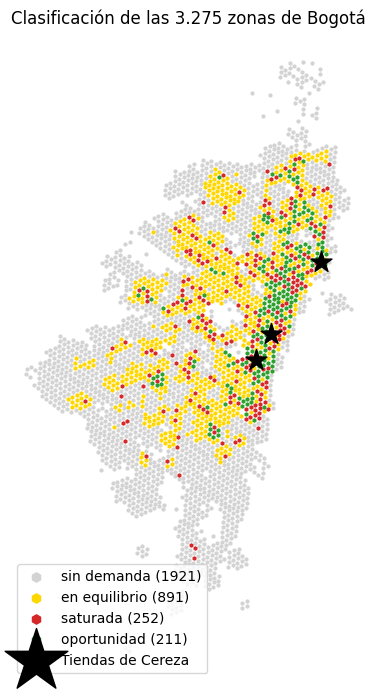

In [32]:
plt.figure(figsize=(6, 7))
for clase in ["sin demanda", "en equilibrio", "saturada", "oportunidad"]:
    t = todas[todas["clase"] == clase]
    plt.scatter(t["lon"], t["lat"], s=5, marker="h", color=COLORES_CLASES[clase], label=clase + " (" + str(len(t)) + ")")
plt.scatter(tiendas["lon"], tiendas["lat"], marker="*", s=250, color="black", label="Tiendas de Cereza")
plt.gca().set_aspect("equal")
plt.axis("off")
plt.legend(markerscale=3, loc="lower left")
plt.title("Clasificación de las 3.275 zonas de Bogotá")
plt.tight_layout()
plt.savefig("fig_mapa_clases.png", dpi=200)
plt.show()

In [33]:
pd.crosstab(todas["segmento"], todas["clase"]).loc[NOMBRES_SEGMENTOS, CLASES]

clase,oportunidad,en equilibrio,saturada,sin demanda
segmento,,,,
Periferia sin actividad,0,0,0,224
Residencial popular,0,0,0,761
Residencial con parques y colegios,2,289,53,826
Corredor comercial,109,542,122,109
Centro de negocios,100,60,77,1


### 11.4 Arriendo que Cereza puede pagar
El valor del suelo no es el arriendo. Supuesto: el arriendo mensual de un local es proporcional al valor del suelo de la zona, y la proporción se calcula con el único dato de arriendo que tenemos: en Chapinero Central un local de 80 m² se arrienda en promedio por 6,5 millones al mes (Fincaraíz, 2026). Se toma el valor del suelo mediano de las zonas a menos de 1 km de la tienda de Chapinero, que está en Chapinero Central.

In [34]:
def distancia_m(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = np.radians(lat1), np.radians(lon1), np.radians(lat2), np.radians(lon2)
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371000 * np.arcsin(np.sqrt(a))

for _, tienda in tiendas.iterrows():
    todas["dist_" + tienda["tienda"]] = distancia_m(todas["lat"], todas["lon"], tienda["lat"], tienda["lon"]).round()
DISTANCIAS = ["dist_" + t for t in tiendas["tienda"]]
todas["dist_tienda_m"] = todas[DISTANCIAS].min(axis=1)
todas["tienda_cercana"] = todas[DISTANCIAS].idxmin(axis=1).str.replace("dist_", "")

SUELO_CHAPINERO = todas.loc[todas["dist_Chapinero"] < 1000, "valor_suelo_m2"].median()
FACTOR_ARRIENDO = ARRIENDO_CHAPINERO * 1e6 / AREA_LOCAL / SUELO_CHAPINERO
todas["arriendo_estimado"] = (FACTOR_ARRIENDO * todas["valor_suelo_m2"] * AREA_LOCAL / 1e6).round(1)
print("Valor del suelo mediano cerca de la tienda de Chapinero:", round(SUELO_CHAPINERO), "por m²")
print("Arriendo mensual por m² =", round(FACTOR_ARRIENDO * 100, 2), "% del valor del suelo por m²")
print("Con 12 millones, Cereza puede pagar zonas con suelo de hasta", round(ARRIENDO_MAXIMO * 1e6 / AREA_LOCAL / FACTOR_ARRIENDO), "por m²")
todas.groupby("clase")["arriendo_estimado"].describe()[["50%", "max"]].loc[CLASES]

Valor del suelo mediano cerca de la tienda de Chapinero: 5000000 por m²
Arriendo mensual por m² = 1.62 % del valor del suelo por m²
Con 12 millones, Cereza puede pagar zonas con suelo de hasta 9230769 por m²


,50%,max
clase,,
oportunidad,5.7,15.2
en equilibrio,4.6,16.2
saturada,5.1,23.1
sin demanda,2.6,16.9


### 11.5 Distancia a las tiendas actuales
Suponemos que un cliente camina a lo sumo unos 10 a 12 minutos por un café, así que una tienda nueva a menos de 1 km de una actual le quitaría clientes. Esas zonas no entran a la lista, pero quedan en el mapa con su distancia para el jefe de operaciones.

In [35]:
oportunidades = todas[todas["clase"] == "oportunidad"]
print("Zonas de oportunidad:", len(oportunidades))
print("Con arriendo que Cereza puede pagar:", (oportunidades["arriendo_estimado"] <= ARRIENDO_MAXIMO).sum())
print("Y a más de", RADIO_CANIBALIZACION, "m de las tiendas:",
      ((oportunidades["arriendo_estimado"] <= ARRIENDO_MAXIMO) & (oportunidades["dist_tienda_m"] >= RADIO_CANIBALIZACION)).sum())

Zonas de oportunidad: 211
Con arriendo que Cereza puede pagar: 210
Y a más de 1000 m de las tiendas: 178


### 11.6 Modelo final como un solo Pipeline
La aplicación necesita un solo objeto de scikit-learn que haga todo: recortar los conteos en el percentil 99, sacar el logaritmo, estandarizar y predecir. Se arma ese `Pipeline` con la misma regresión logística, se entrena con todas las zonas (ya se midió en la prueba) y se revisa que dé las mismas probabilidades que `preparar` más el modelo.

In [36]:
OTRAS = [c for c in ENTRADAS if c in NO_CONTEOS]
tope_final = todas[conteos].quantile(PERCENTIL_TOPE).values
conteos_a_log = Pipeline([("tope", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": tope_final})),
                          ("log", FunctionTransformer(np.log1p))])
preparacion = ColumnTransformer([("conteos", conteos_a_log, conteos), ("otras", "passthrough", OTRAS)])
mi_pipeline = Pipeline([("preparacion", preparacion), ("escala", StandardScaler()),
                        ("modelo", LogisticRegression(C=C_ELEGIDO, max_iter=2000))])
mi_pipeline.fit(todas[ENTRADAS], todas["hay_cafe"])

X_todas = preparar(todas, todas, ENTRADAS, True)
modelo_final = LogisticRegression(C=C_ELEGIDO, max_iter=2000).fit(X_todas, todas["hay_cafe"])
diferencia = np.abs(mi_pipeline.predict_proba(todas[ENTRADAS])[:, 1] - modelo_final.predict_proba(X_todas)[:, 1]).max()
print("Diferencia máxima con preparar + modelo:", round(diferencia, 4))

Diferencia máxima con preparar + modelo: 0.0001


### 11.7 Las 10 mejores zonas para Cereza
Primero se aplica el tope de arriendo de 12 millones al mes y la distancia de 1 km a las tiendas; con las zonas de oportunidad que quedan se arma la lista, ordenada por la brecha (cuántos cafés le faltan) y después por el puntaje. Como las celdas vecinas son casi el mismo lugar, una zona entra a la lista solo si está a más de 500 m de las que ya entraron. Las razones se calculan igual que en la aplicación: cuánto cambia la probabilidad si cada variable toma su valor típico (la mediana de la ciudad); se muestran las tres que más la mueven.

In [37]:
def razones(i):
    fila = todas.loc[[i], ENTRADAS]
    base = mi_pipeline.predict_proba(fila)[0, 1]
    efectos = {}
    for c in ENTRADAS:
        cambiada = fila.copy()
        cambiada[c] = todas[c].median()
        efectos[c] = base - mi_pipeline.predict_proba(cambiada)[0, 1]
    mayores = sorted(efectos, key=lambda c: abs(efectos[c]), reverse=True)[:3]
    textos = []
    for c in mayores:
        sentido = "sube" if efectos[c] > 0 else "baja"
        textos.append(ETIQUETAS[c] + " = " + str(round(fila[c].iloc[0], 2)) + " " + sentido + " " + str(round(abs(efectos[c]) * 100, 1)) + " pts")
    return " · ".join(textos)

candidatas = todas[(todas["clase"] == "oportunidad") & (todas["arriendo_estimado"] <= ARRIENDO_MAXIMO)
                   & (todas["dist_tienda_m"] >= RADIO_CANIBALIZACION)]
elegidas = []
for i, fila in candidatas.sort_values(["brecha", "puntaje"], ascending=False).iterrows():
    lejos = [distancia_m(fila["lat"], fila["lon"], todas.loc[j, "lat"], todas.loc[j, "lon"]) >= SEPARACION_MINIMA for j in elegidas]
    if all(lejos):
        elegidas.append(i)
    if len(elegidas) == 10:
        break
top10 = todas.loc[elegidas].copy()
top10["razones"] = [razones(i) for i in top10.index]
top10["valor_suelo_millones"] = (top10["valor_suelo_m2"] / 1e6).round(2)
top10["margen_despues_arriendo"] = MARGEN_TIENDA - top10["arriendo_estimado"]
top10[["h3", "lat", "lon", "segmento", "puntaje", "n_cafes", "cafes_esperados", "brecha", "valor_suelo_millones",
       "arriendo_estimado", "margen_despues_arriendo", "dist_tienda_m", "tienda_cercana", "razones"]].round(3).reset_index(drop=True)

,h3,lat,lon,segmento,puntaje,n_cafes,cafes_esperados,brecha,valor_suelo_millones,arriendo_estimado,margen_despues_arriendo,dist_tienda_m,tienda_cercana,razones
0,8966e42d6abffff,4.671,-74.053,Centro de negocios,0.926,1,7.273,6.273,8.50,11.0,4.0,2757.0,Chapinero,Entretenimiento a 300 m = 65 sube 4.6 pts · Co...
1,8966e42d663ffff,4.664,-74.062,Centro de negocios,0.941,1,6.422,5.422,4.45,5.8,9.2,1764.0,Chapinero,Oficinas a 300 m = 38 sube 4.4 pts · Comercios...
2,8966e092a87ffff,4.603,-74.079,Centro de negocios,0.864,0,5.234,5.234,7.88,10.2,4.8,3297.0,Teusaquillo,Centros comerciales a 300 m = 19 sube 13.2 pts...
3,8966e09285bffff,4.607,-74.075,Centro de negocios,0.883,0,4.613,4.613,5.22,6.8,8.2,2759.0,Teusaquillo,Centros comerciales a 300 m = 4 sube 10.4 pts ...
4,8966e42d60bffff,4.671,-74.061,Centro de negocios,0.849,0,4.002,4.002,3.86,5.0,10.0,2468.0,Chapinero,Hospitales y clínicas a 300 m = 7 sube 9.3 pts...
5,8966e42d447ffff,4.678,-74.044,Centro de negocios,0.808,0,3.914,3.914,8.06,10.5,4.5,2370.0,Usaquén,Oficinas a 300 m = 20 sube 9.2 pts · Belleza y...
6,8966e092eb7ffff,4.621,-74.071,Centro de negocios,0.894,1,4.892,3.892,4.59,6.0,9.0,1212.0,Teusaquillo,Oficinas a 300 m = 81 sube 6.1 pts · Hospitale...
7,8966e42d68fffff,4.676,-74.055,Centro de negocios,0.859,2,5.774,3.774,8.54,11.1,3.9,3201.0,Chapinero,Oficinas a 300 m = 14 sube 6.9 pts · Oficinas ...
8,8966e42d293ffff,4.661,-74.056,Centro de negocios,0.867,2,5.629,3.629,7.81,10.2,4.8,1505.0,Chapinero,Oficinas a 300 m = 31 sube 6.4 pts · Belleza y...
9,8966e42d6b7ffff,4.674,-74.047,Centro de negocios,0.771,0,3.500,3.500,8.17,10.6,4.4,2973.0,Usaquén,Oficinas a 300 m = 23 sube 10.5 pts · Oficinas...


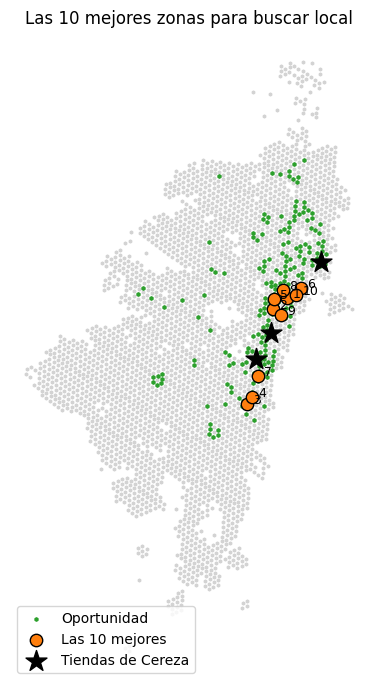

In [38]:
plt.figure(figsize=(6, 7))
plt.scatter(todas["lon"], todas["lat"], s=4, marker="h", color="lightgray")
plt.scatter(oportunidades["lon"], oportunidades["lat"], s=6, marker="h", color="tab:green", label="Oportunidad")
plt.scatter(top10["lon"], top10["lat"], s=80, color="tab:orange", edgecolor="black", label="Las 10 mejores")
for numero, (_, fila) in enumerate(top10.iterrows(), start=1):
    plt.text(fila["lon"] + 0.004, fila["lat"], str(numero), fontsize=9)
plt.scatter(tiendas["lon"], tiendas["lat"], marker="*", s=250, color="black", label="Tiendas de Cereza")
plt.gca().set_aspect("equal")
plt.axis("off")
plt.legend(loc="lower left")
plt.title("Las 10 mejores zonas para buscar local")
plt.tight_layout()
plt.savefig("fig_top10.png", dpi=200)
plt.show()

### 11.8 Cuánto vale el mapa frente a la regla simple
Como en el ejemplo del brief: Cereza estudia zonas hasta encontrar dos aptas. Supuesto: una zona es apta si hoy sostiene al menos un café, que es lo único que podemos comprobar con los datos; la proporción de zonas aptas entre las que marca cada opción es su precisión en las zonas de prueba. El número de estudios para encontrar dos zonas aptas es 2 dividido por esa precisión, y cada estudio cuesta 20 millones. El intervalo sale de las mismas 1.000 muestras de bloques.

In [39]:
COSTO_ESTUDIO = 20
valor = []
for nombre in ["Regla simple", MODELO_ELEGIDO]:
    precision = resultados.loc[nombre, "Precisión"]
    valor.append({"Opción": nombre, "Aptas de cada 10 estudiadas": round(10 * precision, 1),
                  "Estudios para encontrar 2 aptas": round(2 / precision, 1), "Costo de los estudios (M)": round(2 / precision * COSTO_ESTUDIO)})
valor = pd.DataFrame(valor).set_index("Opción")
AHORRO_ESTUDIOS = valor.loc["Regla simple", "Costo de los estudios (M)"] - valor.loc[MODELO_ELEGIDO, "Costo de los estudios (M)"]

precision_regla = muestras.loc[muestras["Opción"] == "Regla simple", "Precisión"].values
precision_modelo = muestras.loc[muestras["Opción"] == MODELO_ELEGIDO, "Precisión"].values
ahorro_muestras = (2 / precision_regla - 2 / precision_modelo) * COSTO_ESTUDIO
IC_AHORRO_ESTUDIOS = np.percentile(ahorro_muestras, [2.5, 97.5]).round()
print("Ahorro en estudios con el modelo:", AHORRO_ESTUDIOS, "M | IC 95 %:", IC_AHORRO_ESTUDIOS)
valor

Ahorro en estudios con el modelo: 3 M | IC 95 %: [-8. 14.]


,Aptas de cada 10 estudiadas,Estudios para encontrar 2 aptas,Costo de los estudios (M)
Opción,,,
Regla simple,3.6,5.5,111
Regresión logística,3.7,5.4,108


La regla y el mapa frente a la clasificación de las zonas: de las zonas de toda la ciudad que la regla mandaría a estudiar, cuántas son oportunidad, cuántas están saturadas y cuántas no tienen demanda.

In [40]:
regla_contra_clases = pd.crosstab(np.where(regla(todas, N_REGLA) == 1, "La regla las estudia", "La regla las descarta"), todas["clase"])[CLASES]
regla_contra_clases

clase,oportunidad,en equilibrio,saturada,sin demanda
row_0,,,,
La regla las descarta,15,135,39,1613
La regla las estudia,196,756,213,308


**Lectura.** Con esta cuenta el mapa casi no ahorra frente a la regla: de cada 10 zonas que marca, 3,7 tienen café, frente a 3,6 con la regla, y para encontrar dos zonas aptas se necesitan 5,4 estudios en lugar de 5,5. Son unos 3 millones menos, con un intervalo que incluye el 0 (de −8 a 14 millones). El costo de los errores dice lo mismo: el modelo cuesta 160 millones menos que la regla en las zonas de prueba, con un intervalo de −820 a +380. Con estos datos no se puede afirmar que el modelo le gane a la regla para escoger qué zonas estudiar, y la recomendación a Cereza lo dice.

El valor del mapa está en lo que la regla no hace. La regla manda a estudiar 1.473 zonas de la ciudad y no distingue entre ellas: 213 están saturadas y 308 no tienen el perfil de demanda. El mapa las separa, deja 211 zonas de oportunidad, les aplica el tope de arriendo (quedan 210) y la distancia a las tiendas (quedan 178) y da las razones de cada una. Y una buena ubicación no garantiza que un café funcione: el local, el concepto y la operación siguen decidiendo, y el estudio de la zona sigue siendo necesario.

## 12. Exportar el modelo a la aplicación
La tabla de resultados que lleva la aplicación tiene, por zona, su código H3, su ubicación, el puntaje fuera de bloque, la clase, los cafés de hoy y los esperados, el arriendo estimado y las distancias a las tiendas. No lleva el archivo original del curso.

In [41]:
tabla_app = todas.copy()
tabla_app["valor_suelo_millones"] = (tabla_app["valor_suelo_m2"] / 1e6).round(2)
tabla_app["cafes_esperados"] = tabla_app["cafes_esperados"].round(2)
tabla_app["brecha"] = tabla_app["brecha"].round(2)
tabla_app["en_prueba"] = (tabla_app["parte"] == "prueba").astype(int)
COLUMNAS_APP = ["lat", "lon", "clase", "segmento", "n_cafes", "cafes_esperados", "brecha", "valor_suelo_millones",
                "arriendo_estimado", "dist_tienda_m", "tienda_cercana"] + DISTANCIAS + ["en_prueba"]

def numero(x):
    return float(round(x, 3))

metricas = {
    "costo_modelo": int(resultados.loc[MODELO_ELEGIDO, "Costo (M)"]),
    "costo_regla": int(resultados.loc["Regla simple", "Costo (M)"]),
    "regla_simple": "Estudiar la zona si tiene " + str(N_REGLA) + " comercios o más a 300 m",
    "unidad_costo": "en millones de pesos (60 por zona con café descartada y 20 por zona sin café estudiada)",
    "intervalo_diferencia": [-float(np.percentile(muestras.loc[muestras["Opción"] == MODELO_ELEGIDO, "Costo (M)"].values - costo_regla_muestras, q)) for q in [97.5, 2.5]],
    "modelo": MODELO_ELEGIDO,
    "zonas_prueba": int(len(prueba)),
    "zonas_prueba_con_cafe": int(real.sum()),
    "sensibilidad_modelo": numero(resultados.loc[MODELO_ELEGIDO, "Sensibilidad"]),
    "sensibilidad_regla": numero(resultados.loc["Regla simple", "Sensibilidad"]),
    "precision_modelo": numero(resultados.loc[MODELO_ELEGIDO, "Precisión"]),
    "precision_regla": numero(resultados.loc["Regla simple", "Precisión"]),
    "estudios_2_aptas_modelo": float(valor.loc[MODELO_ELEGIDO, "Estudios para encontrar 2 aptas"]),
    "estudios_2_aptas_regla": float(valor.loc["Regla simple", "Estudios para encontrar 2 aptas"]),
    "ahorro_estudios": float(AHORRO_ESTUDIOS),
    "intervalo_ahorro_estudios": [float(IC_AHORRO_ESTUDIOS[0]), float(IC_AHORRO_ESTUDIOS[1])],
    "factor_arriendo": float(FACTOR_ARRIENDO),
    "arriendo_maximo": ARRIENDO_MAXIMO,
    "radio_canibalizacion": RADIO_CANIBALIZACION,
    "separacion_minima": SEPARACION_MINIMA,
    "margen_tienda": MARGEN_TIENDA,
    "regla_estudia_por_clase": {c: int(regla_contra_clases.loc["La regla las estudia", c]) for c in CLASES},
    "regla_descarta_por_clase": {c: int(regla_contra_clases.loc["La regla las descarta", c]) for c in CLASES},
    "tabla_modelos": [{"Opción": n, "Costo (M)": int(resultados.loc[n, "Costo (M)"]), "IC 95 %": tabla_final.loc[n, "IC 95 % costo"],
                       "Sensibilidad": numero(resultados.loc[n, "Sensibilidad"]), "Precisión": numero(resultados.loc[n, "Precisión"])}
                      for n in ["Regla simple"] + list(modelos)],
}
metricas

{'costo_modelo': 5940,
 'costo_regla': 6100,
 'regla_simple': 'Estudiar la zona si tiene 51 comercios o más a 300 m',
 'unidad_costo': 'en millones de pesos (60 por zona con café descartada y 20 por zona sin café estudiada)',
 'intervalo_diferencia': [-380.0, 820.0],
 'modelo': 'Regresión logística',
 'zonas_prueba': 732,
 'zonas_prueba_con_cafe': 141,
 'sensibilidad_modelo': 0.681,
 'sensibilidad_regla': 0.681,
 'precision_modelo': 0.372,
 'precision_regla': 0.361,
 'estudios_2_aptas_modelo': 5.4,
 'estudios_2_aptas_regla': 5.5,
 'ahorro_estudios': 3.0,
 'intervalo_ahorro_estudios': [-8.0, 14.0],
 'factor_arriendo': 0.01625,
 'arriendo_maximo': 12,
 'radio_canibalizacion': 1000,
 'separacion_minima': 500,
 'margen_tienda': 15,
 'regla_estudia_por_clase': {'oportunidad': 196,
  'en equilibrio': 756,
  'saturada': 213,
  'sin demanda': 308},
 'regla_descarta_por_clase': {'oportunidad': 15,
  'en equilibrio': 135,
  'saturada': 39,
  'sin demanda': 1613},
 'tabla_modelos': [{'Opción': 'R

In [42]:
if os.path.exists(CARPETA_APP + ".zip") and not os.path.exists(CARPETA_APP):
    zipfile.ZipFile(CARPETA_APP + ".zip").extractall()
print("¿Está la plantilla?", os.path.exists(CARPETA_APP))

¿Está la plantilla? True


In [43]:
if os.path.exists(CARPETA_APP):
    sys.path.append(CARPETA_APP)
    from exportar import exportar
    exportar(
        modelo=mi_pipeline,
        X_entrenamiento=todas[ENTRADAS],
        umbrales=[float(UMBRAL)],
        decisiones=["No estudiar", "Estudiar la zona"],
        metricas=metricas,
        evento="tener café",
        tabla_resultados=tabla_app,
        probabilidad_resultados=todas["puntaje"],
        columna_id="h3",
        columnas_a_mostrar=COLUMNAS_APP,
        etiquetas=ETIQUETAS,
    )

Calculando las razones de 3275 filas...
   razones: 3000 de 3275 filas

Listo: /content/plantilla_app/model y requirements.txt actualizados con estas versiones:
   scikit-learn==1.6.1
   pandas==2.2.3
   numpy==2.4.6
   joblib==1.6.0
Modelo exportado con Python 3.13: elijan esa versión al publicar en Streamlit.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Siguiente paso: desplegar (python desplegar.py, o desplegar(...) en Colab).


In [44]:
if os.path.exists(CARPETA_APP):
    from desplegar import desplegar
    desplegar(CARPETA_APP)

Entorno detectado: Google Colab (Python 3.13.18). Carpeta de la app: /content/plantilla_app

1. Instalar las librerías de requirements.txt
Listo.

2. Revisar la app con check.py
Revisando la app...

[OK]    archivos de la plantilla
[OK]    zona fija sin cambios
[OK]    mi_app.py completo
[OK]    modelo exportado con sus métricas: 27 variables, umbrales [0.23], decisiones ['No estudiar', 'Estudiar la zona']
[OK]    versiones en requirements.txt
[OK]    el modelo carga, predice y explica: 16% → No estudiar, 2% → No estudiar, 71% → Estudiar la zona
[OK]    resultados.csv: 3275 filas. Revisen que cumpla las condiciones de uso de los datos de su caso
[OK]    la opción HTML se arma: 3.7 MB
[OK]    el repositorio no lleva los datos del curso
[OK]    pie de página y marca de datos del HTML
[OK]    app.py corre de principio a fin

LISTO PARA DESPLEGAR


3. Probar la app
Abran el enlace que aparece abajo para probar la app (funciona mientras esta sesión de Colab esté activa).
Try `serve_kernel_p

<IPython.core.display.Javascript object>


4. Archivos para GitHub
Quedó para_subir_a_github.zip con 18 archivos (sin datos del curso).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Cómo subirlos a GitHub desde el navegador:
  a. Descompriman el .zip en su computador.
  b. En github.com abran su repositorio privado (o créenlo en https://github.com/new).
  c. Elijan "Add file" → "Upload files" y arrastren TODO el contenido de la carpeta descomprimida
     (las carpetas también), no la carpeta misma.
  d. Abajo, escriban un mensaje corto y presionen "Commit changes".
  Si ya habían subido una versión, suban los archivos otra vez: GitHub reemplaza los que cambiaron.

5. Publicar en Streamlit Community Cloud
  a. Entren a https://share.streamlit.io con su cuenta de GitHub.
     La primera vez, autoricen el acceso a sus repositorios privados.
  b. Elijan "Create app" y la opción de desplegar desde un repositorio de GitHub
     (la app queda pública; el repositorio sigue privado).
  c. Repository: su repositorio. Branch: main. Main file path: app.py
  d. En "Advanced settings" elijan Python 3.13 (la misma versión con que exportaron el modelo).
  e. Presionen "Deploy" y